# LabDSS Website RECSYS
Nguyễn Hoàng Hà · MSSV 102230343 · Báo cáo cá nhân · 28/10/2026

Notebook này đọc MEDAJob thật, chạy chín thuật toán và phân biệt hai mục tiêu: đối sánh một snapshot đầy đủ với website, và đánh giá ngoại tuyến trên train/test. Không dùng dữ liệu demo, không đăng nhập hoặc ghi lên website.

**Kết luận về tài khoản:** `sv102230343` vắng mặt trong dữ liệu gốc. Bản xuất website có user `458`, chưa có hồ sơ kỹ năng và rating. Không thay bằng người dùng khác. Kết quả dự phòng không được diễn giải như sở thích của sinh viên.

Chạy từ đầu bằng `python scripts/execute_notebook.py` trong môi trường đã cài `requirements.txt`. Dữ liệu gốc được ưu tiên; gói chia sẻ chỉ có các bản đã lược bỏ thông tin cá nhân, có provenance và mã snapshot riêng. Không sửa nguồn CSV trong notebook.

In [1]:
from pathlib import Path
import json
from dataclasses import asdict, replace
import pandas as pd
import numpy as np
from IPython.display import display, Markdown, Image
from job_recsys.data import load_dataset, split_skills
from job_recsys.models import ALGORITHMS, Config, RecommenderSuite, content_scores
from job_recsys.evaluation import positive_holdout, compare_website
from job_recsys.run import run

ROOT = Path.cwd()
assert (ROOT / "job_recsys").is_dir(), "Mở notebook từ thư mục Lab3"
cfg_values = json.loads((ROOT / "configs/experiment.json").read_text(encoding="utf-8"))
config = Config(**{k:v for k,v in cfg_values.items() if k in Config.__dataclass_fields__})
target_username = cfg_values["target_username"]
data_paths = {
    "provided_snapshot": Path("data_MEDAJOB"),
    "website_before": Path("data/raw/website_before/csv"),
    "website_after_capture": Path("data/raw/website_after_capture/csv"),
}
for label, path in list(data_paths.items()):
    if not path.is_dir():
        data_paths[label] = Path("data/shared") / label
    assert data_paths[label].is_dir(), f"Thiếu dữ liệu thật: {label}"
display(pd.DataFrame([{"snapshot":k,"path":str(v),"privacy_reduced":"shared" in v.parts} for k,v in data_paths.items()]))
display(pd.DataFrame(asdict(config).items(), columns=["Tham số", "Giá trị"]))

,snapshot,path,privacy_reduced
0,provided_snapshot,data_MEDAJOB,False
1,website_before,data\raw\website_before\csv,False
2,website_after_capture,data\raw\website_after_capture\csv,False


,Tham số,Giá trị
0,top_n,10
1,seed,42
2,similarity,cosine
3,positive_threshold,4.0
4,view_weight,0.25
5,hybrid_alpha,0.55
6,knn_k,5
7,popularity_prior,5.0
8,factors,12
9,sgd_epochs,45


## 1 Đọc dữ liệu và kiểm tra chất lượng
Nối `users.id = user_profiles.user_id`. ID đọc dạng chuỗi, không làm mất số 0 đầu. Kỹ năng JSON array hoặc chuỗi phân cách bằng dấu phẩy/chấm phẩy/dấu gạch đứng được chuẩn hóa Unicode NFC và chữ thường; không cắt cụm như `machine learning` theo khoảng trắng.

Pipeline dừng khi có ID trùng, khóa ngoại sai, cặp rating trùng không có thời gian đáng tin cậy, rating ngoài 1–5 hoặc thời lượng xem không hữu hạn/âm. Giữ toàn bộ user và job, kể cả job chưa được rating. `status=open` là quy tắc ứng viên chung; chưa suy diễn hạn nộp lịch sử từ metadata không hoàn chỉnh.

In [2]:
datasets = {label: load_dataset(path) for label,path in data_paths.items()}
quality = []
for label,d in datasets.items():
    q = d.quality
    quality.append({"snapshot":label,"hash":d.snapshot_id,"users":len(d.users),"jobs":len(d.jobs),
                    "ratings":len(d.ratings),"view_pairs":len(d.views),"rating_users":q["rating_users"],
                    "users_without_skills":q["users_without_skills"],"sparsity":q["sparsity_all_users"]})
display(pd.DataFrame(quality))
print(split_skills('["Python", "machine learning", "SQL"]'))
for label,d in datasets.items():
    t=d.users[d.users.username.eq(target_username)]
    print(label, "target absent" if t.empty else {"user_id":t.iloc[0].user_id,"skills":t.iloc[0].skill_list,
          "ratings":int(d.ratings.user_id.eq(t.iloc[0].user_id).sum())})

,snapshot,hash,users,jobs,ratings,view_pairs,rating_users,users_without_skills,sparsity
0,provided_snapshot,7b33ca0861b04b83,345,791,104,680,34,311,0.999619
1,website_before,51408df1d5bcdeb8,466,1168,169,0,13,399,0.999690
2,website_after_capture,f6582d5747ac1d61,466,1189,211,0,15,399,0.999619


['machine learning', 'python', 'sql']
provided_snapshot target absent
website_before {'user_id': '458', 'skills': [], 'ratings': 0}
website_after_capture {'user_id': '458', 'skills': [], 'ratings': 0}


## 2 Tín hiệu và quy tắc chung
Rating explicit dùng riêng ma trận $R$ và mask quan sát $M$. Không xem số 0 bị thiếu là rating thật.

Tín hiệu hành vi $B_{ui}=r_{ui}/5$ nếu rating ≥4; $B_{ui}=0.25$ nếu cặp chưa rating nhưng có thời lượng xem dương; các trường hợp còn lại bằng 0. Rating thấp luôn chặn lượt xem của cùng cặp. Lượt xem lặp được gộp, không tăng trọng số tùy số lần mở trang.

Top-N=10, seed=42; loại việc đã rating và việc không mở. Khi đồng điểm, sắp ID tăng dần. Điểm model và điểm dự phòng có thang khác nhau: các ứng viên có bằng chứng model được xếp trước dự phòng Popularity. Mọi fallback có nhãn, không clip các điểm rating để tránh tạo đồng hạng giả.

## 3 Chạy snapshot đầy đủ và holdout độc lập
`fit(dataset)` học trên dữ liệu truyền vào; `recommend(user_id, top_n, algorithms)` trả thuật toán, user/job ID, hạng, điểm, loại điểm, fallback và snapshot ID. Không tự chọn user đầu tiên.

Hàm `run` vừa xuất đối sánh full-snapshot, vừa tạo mô hình train riêng cho đánh giá. Bản gốc và các lần xuất website chạy độc lập, không trộn rating giữa snapshot.

In [3]:
web_path = Path("data/website/verified_baseline/recommendations.csv")
capture_path = Path("data/website/verified_baseline/capture_manifest.json")
web = pd.read_csv(web_path, dtype={"user_id":str,"job_id":str})
captures = json.loads(capture_path.read_text(encoding="utf-8"))
runs = {}
for label,path in data_paths.items():
    runs[label] = run(path, Path("outputs/notebook")/label, target_username, config,
                      web_path if label != "provided_snapshot" else None,
                      capture_path if label != "provided_snapshot" else None)
data, suite, recs, metrics, manifest = runs["website_before"]
target_id = manifest["target_user_id"]
display(recs.groupby(["algorithm","score_type","status"], dropna=False).size().rename("count").reset_index())

{"dataset_snapshot_id": "7b33ca0861b04b83", "target_user_id": null, "target_status": "absent_from_snapshot", "recommendation_rows": 0, "test_users": 34, "duration_seconds": 31.111}


{"dataset_snapshot_id": "51408df1d5bcdeb8", "target_user_id": "458", "target_status": "profile_missing", "recommendation_rows": 90, "test_users": 11, "duration_seconds": 17.212}


{"dataset_snapshot_id": "f6582d5747ac1d61", "target_user_id": "458", "target_status": "profile_missing", "recommendation_rows": 90, "test_users": 14, "duration_seconds": 21.235}


,algorithm,score_type,status,count
0,als_explicit,bayesian_rating_prior,fallback,10
1,als_implicit,bayesian_rating_prior,fallback,10
2,cbf,bayesian_rating_prior,fallback,10
3,cf,bayesian_rating_prior,fallback,10
4,hybrid,bayesian_rating_prior,fallback,10
5,item_knn,bayesian_rating_prior,fallback,10
6,popularity,predicted_rating,model,10
7,sgd,bayesian_rating_prior,fallback,10
8,user_knn,bayesian_rating_prior,fallback,10


## 4 1 CBF theo kỹ năng
$s(u,j)=x_u^T x_j/(\|x_u\|\|x_j\|)$ trên vector nhị phân kỹ năng. Jaccard = giao/hợp; Pearson = cosine của vector đã trừ trung bình. Hồ sơ rỗng dùng Popularity có nhãn; job rỗng có nội dung bằng 0. CBF này chỉ dùng kỹ năng, không giả định backend website dùng cùng đặc trưng.

Bảng sau là Top-10 của đúng user 458 trong snapshot trước thu ảnh. Ảnh là kết quả website có nhãn thuật toán đã kiểm tra; hai bên không có cam kết đồng nhất backend hoặc snapshot.

,rank,job_id,title,score,score_type,fallback
0,1,838,Java Fullstack Developer,4.467456,bayesian_rating_prior,popularity_missing_profile
1,2,1865,"AI Engineer (NLP, LLM, AI Agent)",4.467456,bayesian_rating_prior,popularity_missing_profile
2,3,1884,"AI Engineer (Python, LLM, RAG)",4.415516,bayesian_rating_prior,popularity_missing_profile
3,4,1899,Senior Python Developer / Backend Engineer,4.415516,bayesian_rating_prior,popularity_missing_profile
4,5,1901,AI / Machine Learning Engineer (Recommender Sy...,4.415516,bayesian_rating_prior,popularity_missing_profile
5,6,1878,Machine Learning Engineer,4.391378,bayesian_rating_prior,popularity_missing_profile
6,7,1903,Senior Fullstack Developer (Python & ReactJS),4.391378,bayesian_rating_prior,popularity_missing_profile
7,8,1945,Lập Trình Viên Ứng Dụng Đa Nền Tảng (Desktop/W...,4.391378,bayesian_rating_prior,popularity_missing_profile
8,9,1908,QA Automation Test Engineer (Python / Playwright),4.373964,bayesian_rating_prior,popularity_missing_profile
9,10,1894,Fresher AI Engineer (Đào tạo 3 tháng),4.342456,bayesian_rating_prior,popularity_missing_profile


,k,test_users,hit_rate,recall,ndcg,catalog_coverage,fallback_fraction,rmse_positive_holdout,mae_positive_holdout
0,5,11,0.0,0.0,0.0,0.030541,0.0,NaN,NaN
1,10,11,0.0,0.0,0.0,0.055846,0.0,NaN,NaN


Website trả **10** kết quả, HTTP 200; thời điểm UTC 2026-10-28T07:46:55.843Z.

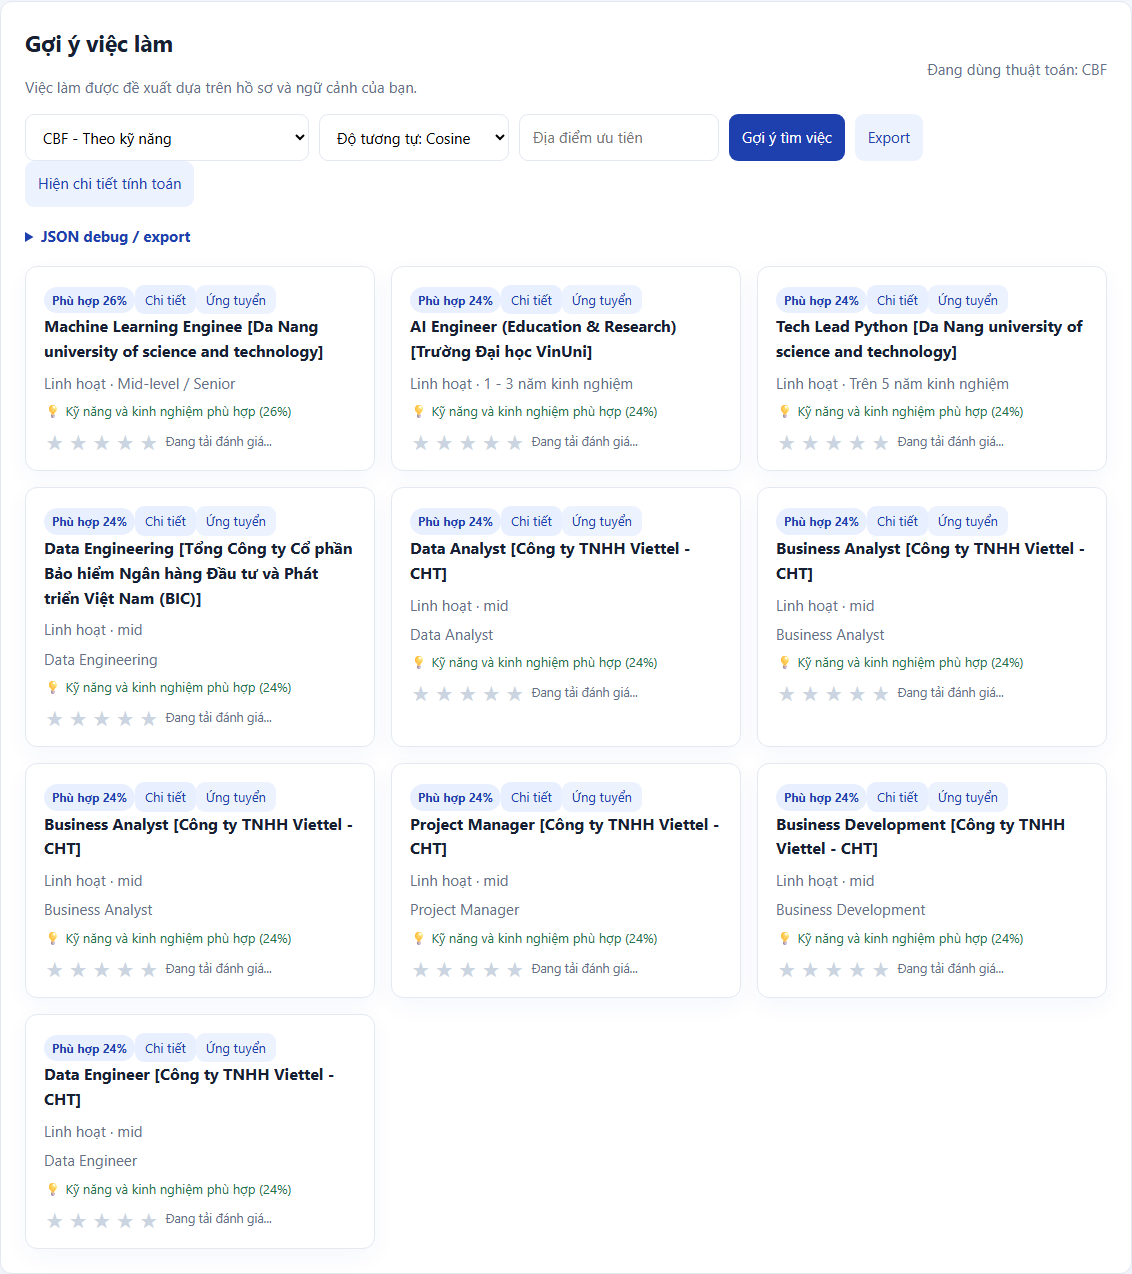

In [4]:
display(recs[recs.algorithm.eq("cbf")][["rank","job_id","title","score","score_type","fallback"]])
display(metrics[metrics.algorithm.eq("cbf")][["k","test_users","hit_rate","recall","ndcg","catalog_coverage","fallback_fraction","rmse_positive_holdout","mae_positive_holdout"]])
cap=next(c for c in captures if c["algorithm"]=="cbf" and c["similarity"]=="cosine")
display(Markdown(f"Website trả **{cap['n_items']}** kết quả, HTTP {cap['http_status']}; thời điểm UTC {cap['captured_at']}."))
display(Image(filename=cap["screenshot"],width=1000))

## 4 2 CF theo hành vi
Tính cosine giữa các cột của $B$, bỏ đường chéo. Điểm job là tổng có trọng số các tương đồng với hành vi dương của user, chia cho $\max(\sum_i B_{ui},1)$. Không có hỗ trợ đồng xuất hiện thì dùng dự phòng.

Bảng sau là Top-10 của đúng user 458 trong snapshot trước thu ảnh. Ảnh là kết quả website có nhãn thuật toán đã kiểm tra; hai bên không có cam kết đồng nhất backend hoặc snapshot.

,rank,job_id,title,score,score_type,fallback
10,1,838,Java Fullstack Developer,4.467456,bayesian_rating_prior,popularity_no_behavior_support
11,2,1865,"AI Engineer (NLP, LLM, AI Agent)",4.467456,bayesian_rating_prior,popularity_no_behavior_support
12,3,1884,"AI Engineer (Python, LLM, RAG)",4.415516,bayesian_rating_prior,popularity_no_behavior_support
13,4,1899,Senior Python Developer / Backend Engineer,4.415516,bayesian_rating_prior,popularity_no_behavior_support
14,5,1901,AI / Machine Learning Engineer (Recommender Sy...,4.415516,bayesian_rating_prior,popularity_no_behavior_support
15,6,1878,Machine Learning Engineer,4.391378,bayesian_rating_prior,popularity_no_behavior_support
16,7,1903,Senior Fullstack Developer (Python & ReactJS),4.391378,bayesian_rating_prior,popularity_no_behavior_support
17,8,1945,Lập Trình Viên Ứng Dụng Đa Nền Tảng (Desktop/W...,4.391378,bayesian_rating_prior,popularity_no_behavior_support
18,9,1908,QA Automation Test Engineer (Python / Playwright),4.373964,bayesian_rating_prior,popularity_no_behavior_support
19,10,1894,Fresher AI Engineer (Đào tạo 3 tháng),4.342456,bayesian_rating_prior,popularity_no_behavior_support


,k,test_users,hit_rate,recall,ndcg,catalog_coverage,fallback_fraction,rmse_positive_holdout,mae_positive_holdout
2,5,11,0.454545,0.454545,0.256139,0.026178,0.090909,NaN,NaN
3,10,11,0.545455,0.545455,0.288522,0.039267,0.090909,NaN,NaN


Website trả **0** kết quả, HTTP 200; thời điểm UTC 2026-10-28T07:39:57.923Z.

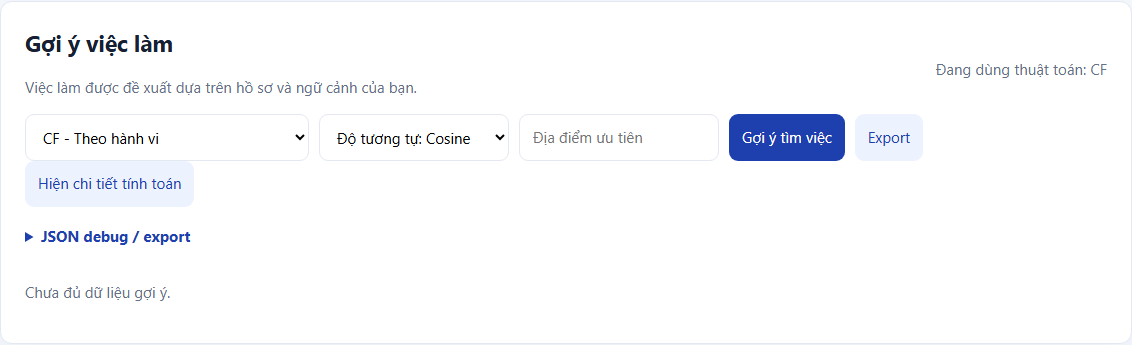

In [5]:
display(recs[recs.algorithm.eq("cf")][["rank","job_id","title","score","score_type","fallback"]])
display(metrics[metrics.algorithm.eq("cf")][["k","test_users","hit_rate","recall","ndcg","catalog_coverage","fallback_fraction","rmse_positive_holdout","mae_positive_holdout"]])
cap=next(c for c in captures if c["algorithm"]=="cf" and c["similarity"]=="cosine")
display(Markdown(f"Website trả **{cap['n_items']}** kết quả, HTTP {cap['http_status']}; thời điểm UTC {cap['captured_at']}."))
display(Image(filename=cap["screenshot"],width=1000))

## 4 3 Hybrid kết hợp
$s=0.55\,norm(s_{CBF})+0.45\,norm(s_{CF})$, với norm là min-max theo user. Không trộn điểm rating dự phòng vào affinity CF. Thiếu một nhánh thì dùng nhánh còn lại có nhãn; thiếu cả hai dùng Popularity.

Bảng sau là Top-10 của đúng user 458 trong snapshot trước thu ảnh. Ảnh là kết quả website có nhãn thuật toán đã kiểm tra; hai bên không có cam kết đồng nhất backend hoặc snapshot.

,rank,job_id,title,score,score_type,fallback
20,1,838,Java Fullstack Developer,4.467456,bayesian_rating_prior,popularity_no_profile_or_behavior
21,2,1865,"AI Engineer (NLP, LLM, AI Agent)",4.467456,bayesian_rating_prior,popularity_no_profile_or_behavior
22,3,1884,"AI Engineer (Python, LLM, RAG)",4.415516,bayesian_rating_prior,popularity_no_profile_or_behavior
23,4,1899,Senior Python Developer / Backend Engineer,4.415516,bayesian_rating_prior,popularity_no_profile_or_behavior
24,5,1901,AI / Machine Learning Engineer (Recommender Sy...,4.415516,bayesian_rating_prior,popularity_no_profile_or_behavior
25,6,1878,Machine Learning Engineer,4.391378,bayesian_rating_prior,popularity_no_profile_or_behavior
26,7,1903,Senior Fullstack Developer (Python & ReactJS),4.391378,bayesian_rating_prior,popularity_no_profile_or_behavior
27,8,1945,Lập Trình Viên Ứng Dụng Đa Nền Tảng (Desktop/W...,4.391378,bayesian_rating_prior,popularity_no_profile_or_behavior
28,9,1908,QA Automation Test Engineer (Python / Playwright),4.373964,bayesian_rating_prior,popularity_no_profile_or_behavior
29,10,1894,Fresher AI Engineer (Đào tạo 3 tháng),4.342456,bayesian_rating_prior,popularity_no_profile_or_behavior


,k,test_users,hit_rate,recall,ndcg,catalog_coverage,fallback_fraction,rmse_positive_holdout,mae_positive_holdout
4,5,11,0.181818,0.181818,0.084607,0.035777,0.0,NaN,NaN
5,10,11,0.272727,0.272727,0.111973,0.059337,0.0,NaN,NaN


Website trả **10** kết quả, HTTP 200; thời điểm UTC 2026-10-28T07:40:39.620Z.

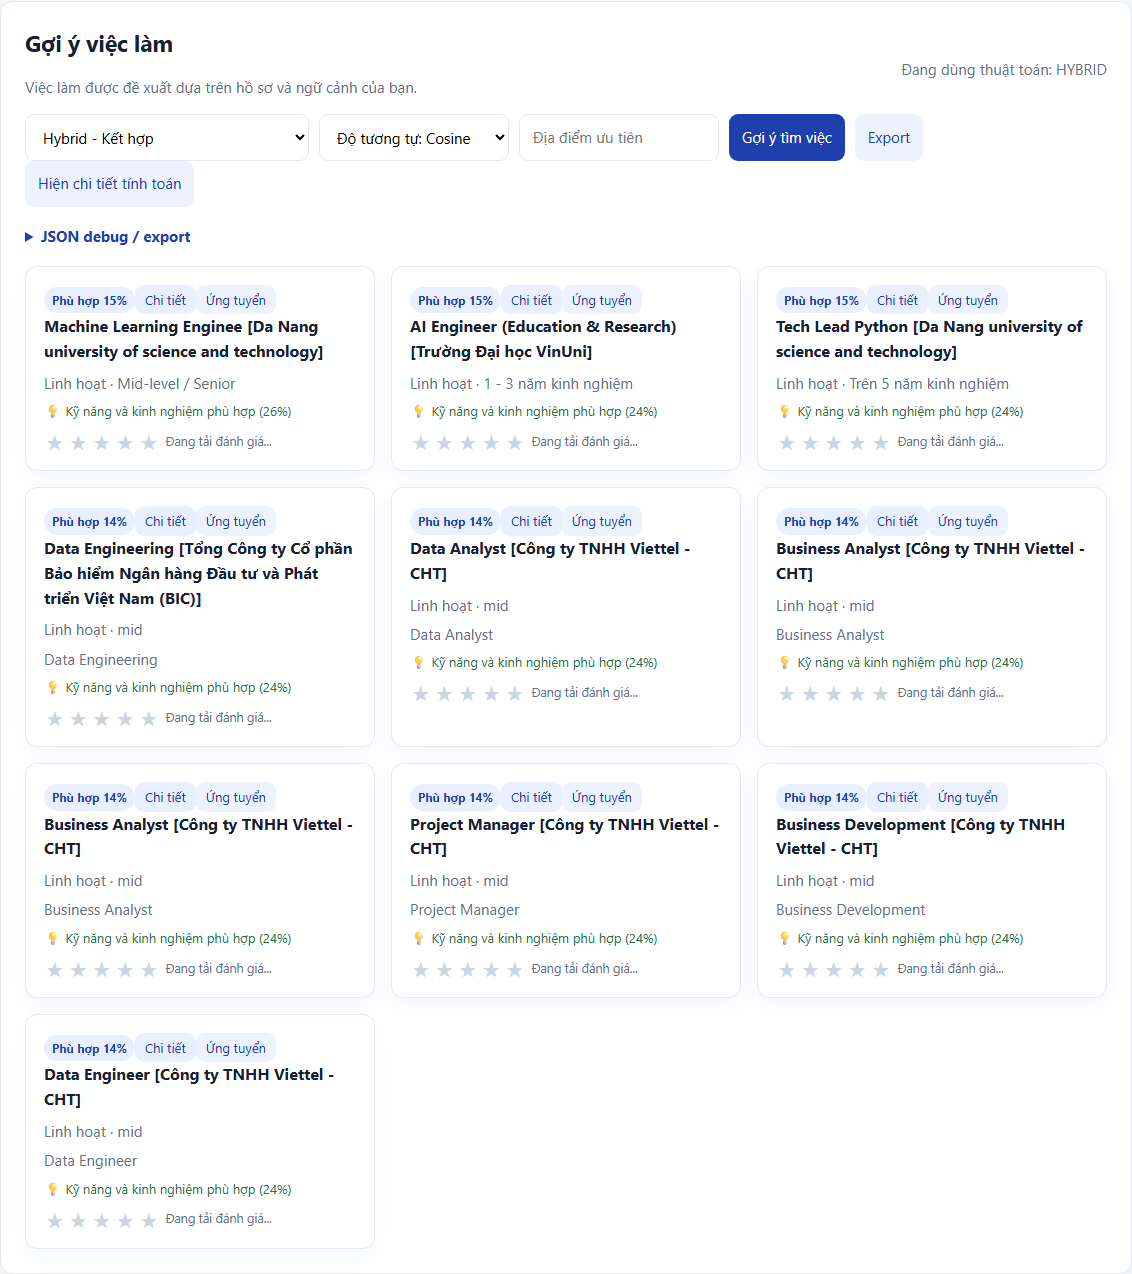

In [6]:
display(recs[recs.algorithm.eq("hybrid")][["rank","job_id","title","score","score_type","fallback"]])
display(metrics[metrics.algorithm.eq("hybrid")][["k","test_users","hit_rate","recall","ndcg","catalog_coverage","fallback_fraction","rmse_positive_holdout","mae_positive_holdout"]])
cap=next(c for c in captures if c["algorithm"]=="hybrid" and c["similarity"]=="cosine")
display(Markdown(f"Website trả **{cap['n_items']}** kết quả, HTTP {cap['http_status']}; thời điểm UTC {cap['captured_at']}."))
display(Image(filename=cap["screenshot"],width=1000))

## 4 4 User KNN
Chọn tối đa 5 user có cosine cao nhất trên vector rating, loại chính user. $\hat r_{uj}=\sum_v sim(u,v)r_{vj}/\sum_v sim(u,v)M_{vj}$. Mẫu số chỉ gồm người đã rating job. Không có láng giềng hợp lệ dùng Popularity.

Bảng sau là Top-10 của đúng user 458 trong snapshot trước thu ảnh. Ảnh là kết quả website có nhãn thuật toán đã kiểm tra; hai bên không có cam kết đồng nhất backend hoặc snapshot.

,rank,job_id,title,score,score_type,fallback
30,1,838,Java Fullstack Developer,4.467456,bayesian_rating_prior,popularity_no_neighbors
31,2,1865,"AI Engineer (NLP, LLM, AI Agent)",4.467456,bayesian_rating_prior,popularity_no_neighbors
32,3,1884,"AI Engineer (Python, LLM, RAG)",4.415516,bayesian_rating_prior,popularity_no_neighbors
33,4,1899,Senior Python Developer / Backend Engineer,4.415516,bayesian_rating_prior,popularity_no_neighbors
34,5,1901,AI / Machine Learning Engineer (Recommender Sy...,4.415516,bayesian_rating_prior,popularity_no_neighbors
35,6,1878,Machine Learning Engineer,4.391378,bayesian_rating_prior,popularity_no_neighbors
36,7,1903,Senior Fullstack Developer (Python & ReactJS),4.391378,bayesian_rating_prior,popularity_no_neighbors
37,8,1945,Lập Trình Viên Ứng Dụng Đa Nền Tảng (Desktop/W...,4.391378,bayesian_rating_prior,popularity_no_neighbors
38,9,1908,QA Automation Test Engineer (Python / Playwright),4.373964,bayesian_rating_prior,popularity_no_neighbors
39,10,1894,Fresher AI Engineer (Đào tạo 3 tháng),4.342456,bayesian_rating_prior,popularity_no_neighbors


,k,test_users,hit_rate,recall,ndcg,catalog_coverage,fallback_fraction,rmse_positive_holdout,mae_positive_holdout
6,5,11,0.090909,0.090909,0.035168,0.015707,0.090909,0.858851,0.699783
7,10,11,0.181818,0.181818,0.067551,0.025305,0.090909,0.858851,0.699783


Website trả **0** kết quả, HTTP 200; thời điểm UTC 2026-10-28T07:41:50.756Z.

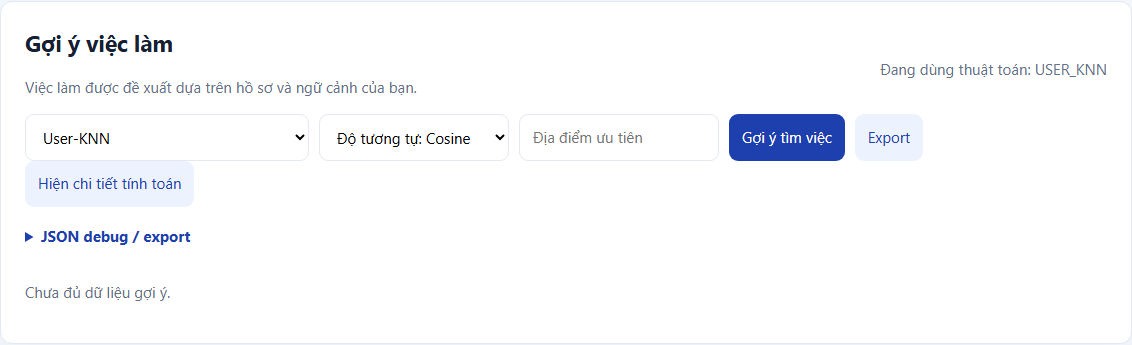

In [7]:
display(recs[recs.algorithm.eq("user_knn")][["rank","job_id","title","score","score_type","fallback"]])
display(metrics[metrics.algorithm.eq("user_knn")][["k","test_users","hit_rate","recall","ndcg","catalog_coverage","fallback_fraction","rmse_positive_holdout","mae_positive_holdout"]])
cap=next(c for c in captures if c["algorithm"]=="user_knn" and c["similarity"]=="cosine")
display(Markdown(f"Website trả **{cap['n_items']}** kết quả, HTTP {cap['http_status']}; thời điểm UTC {cap['captured_at']}."))
display(Image(filename=cap["screenshot"],width=1000))

## 4 5 Item KNN
Chọn tối đa 5 job có cosine cao nhất trên cột rating, bỏ chính job. $\hat r_{uj}=\sum_i sim(j,i)r_{ui}/\sum_i sim(j,i)M_{ui}$. Giữ mask quan sát; không coi missing là đánh giá 0.

Bảng sau là Top-10 của đúng user 458 trong snapshot trước thu ảnh. Ảnh là kết quả website có nhãn thuật toán đã kiểm tra; hai bên không có cam kết đồng nhất backend hoặc snapshot.

,rank,job_id,title,score,score_type,fallback
40,1,838,Java Fullstack Developer,4.467456,bayesian_rating_prior,popularity_no_neighbors
41,2,1865,"AI Engineer (NLP, LLM, AI Agent)",4.467456,bayesian_rating_prior,popularity_no_neighbors
42,3,1884,"AI Engineer (Python, LLM, RAG)",4.415516,bayesian_rating_prior,popularity_no_neighbors
43,4,1899,Senior Python Developer / Backend Engineer,4.415516,bayesian_rating_prior,popularity_no_neighbors
44,5,1901,AI / Machine Learning Engineer (Recommender Sy...,4.415516,bayesian_rating_prior,popularity_no_neighbors
45,6,1878,Machine Learning Engineer,4.391378,bayesian_rating_prior,popularity_no_neighbors
46,7,1903,Senior Fullstack Developer (Python & ReactJS),4.391378,bayesian_rating_prior,popularity_no_neighbors
47,8,1945,Lập Trình Viên Ứng Dụng Đa Nền Tảng (Desktop/W...,4.391378,bayesian_rating_prior,popularity_no_neighbors
48,9,1908,QA Automation Test Engineer (Python / Playwright),4.373964,bayesian_rating_prior,popularity_no_neighbors
49,10,1894,Fresher AI Engineer (Đào tạo 3 tháng),4.342456,bayesian_rating_prior,popularity_no_neighbors


,k,test_users,hit_rate,recall,ndcg,catalog_coverage,fallback_fraction,rmse_positive_holdout,mae_positive_holdout
8,5,11,0.272727,0.272727,0.183435,0.022688,0.309091,0.910081,0.715615
9,10,11,0.727273,0.727273,0.326044,0.027923,0.436364,0.910081,0.715615


Website trả **0** kết quả, HTTP 200; thời điểm UTC 2026-10-28T07:42:22.099Z.

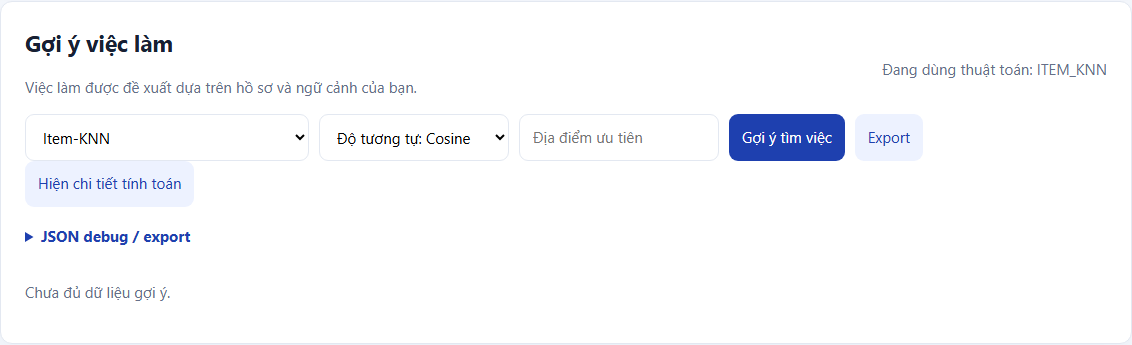

In [8]:
display(recs[recs.algorithm.eq("item_knn")][["rank","job_id","title","score","score_type","fallback"]])
display(metrics[metrics.algorithm.eq("item_knn")][["k","test_users","hit_rate","recall","ndcg","catalog_coverage","fallback_fraction","rmse_positive_holdout","mae_positive_holdout"]])
cap=next(c for c in captures if c["algorithm"]=="item_knn" and c["similarity"]=="cosine")
display(Markdown(f"Website trả **{cap['n_items']}** kết quả, HTTP {cap['http_status']}; thời điểm UTC {cap['captured_at']}."))
display(Image(filename=cap["screenshot"],width=1000))

## 4 6 Popularity
Baseline dùng trung bình Bayes $s_j=(\sum_u r_{uj}+5\mu)/(n_j+5)$. Đây là biến thể chất lượng rating có prior, không phải bộ đếm lượt xem. Khi không có rating toàn bộ dữ liệu, prior trung tính =3 và có nhãn.

Bảng sau là Top-10 của đúng user 458 trong snapshot trước thu ảnh. Ảnh là kết quả website có nhãn thuật toán đã kiểm tra; hai bên không có cam kết đồng nhất backend hoặc snapshot.

,rank,job_id,title,score,score_type,fallback
50,1,838,Java Fullstack Developer,4.467456,predicted_rating,
51,2,1865,"AI Engineer (NLP, LLM, AI Agent)",4.467456,predicted_rating,
52,3,1884,"AI Engineer (Python, LLM, RAG)",4.415516,predicted_rating,
53,4,1899,Senior Python Developer / Backend Engineer,4.415516,predicted_rating,
54,5,1901,AI / Machine Learning Engineer (Recommender Sy...,4.415516,predicted_rating,
55,6,1878,Machine Learning Engineer,4.391378,predicted_rating,
56,7,1903,Senior Fullstack Developer (Python & ReactJS),4.391378,predicted_rating,
57,8,1945,Lập Trình Viên Ứng Dụng Đa Nền Tảng (Desktop/W...,4.391378,predicted_rating,
58,9,1908,QA Automation Test Engineer (Python / Playwright),4.373964,predicted_rating,
59,10,1894,Fresher AI Engineer (Đào tạo 3 tháng),4.342456,predicted_rating,


,k,test_users,hit_rate,recall,ndcg,catalog_coverage,fallback_fraction,rmse_positive_holdout,mae_positive_holdout
10,5,11,0.181818,0.181818,0.092526,0.009599,0.0,0.457291,0.395255
11,10,11,0.454545,0.454545,0.183569,0.015707,0.0,0.457291,0.395255


Website trả **10** kết quả, HTTP 200; thời điểm UTC 2026-10-28T07:39:01.957Z.

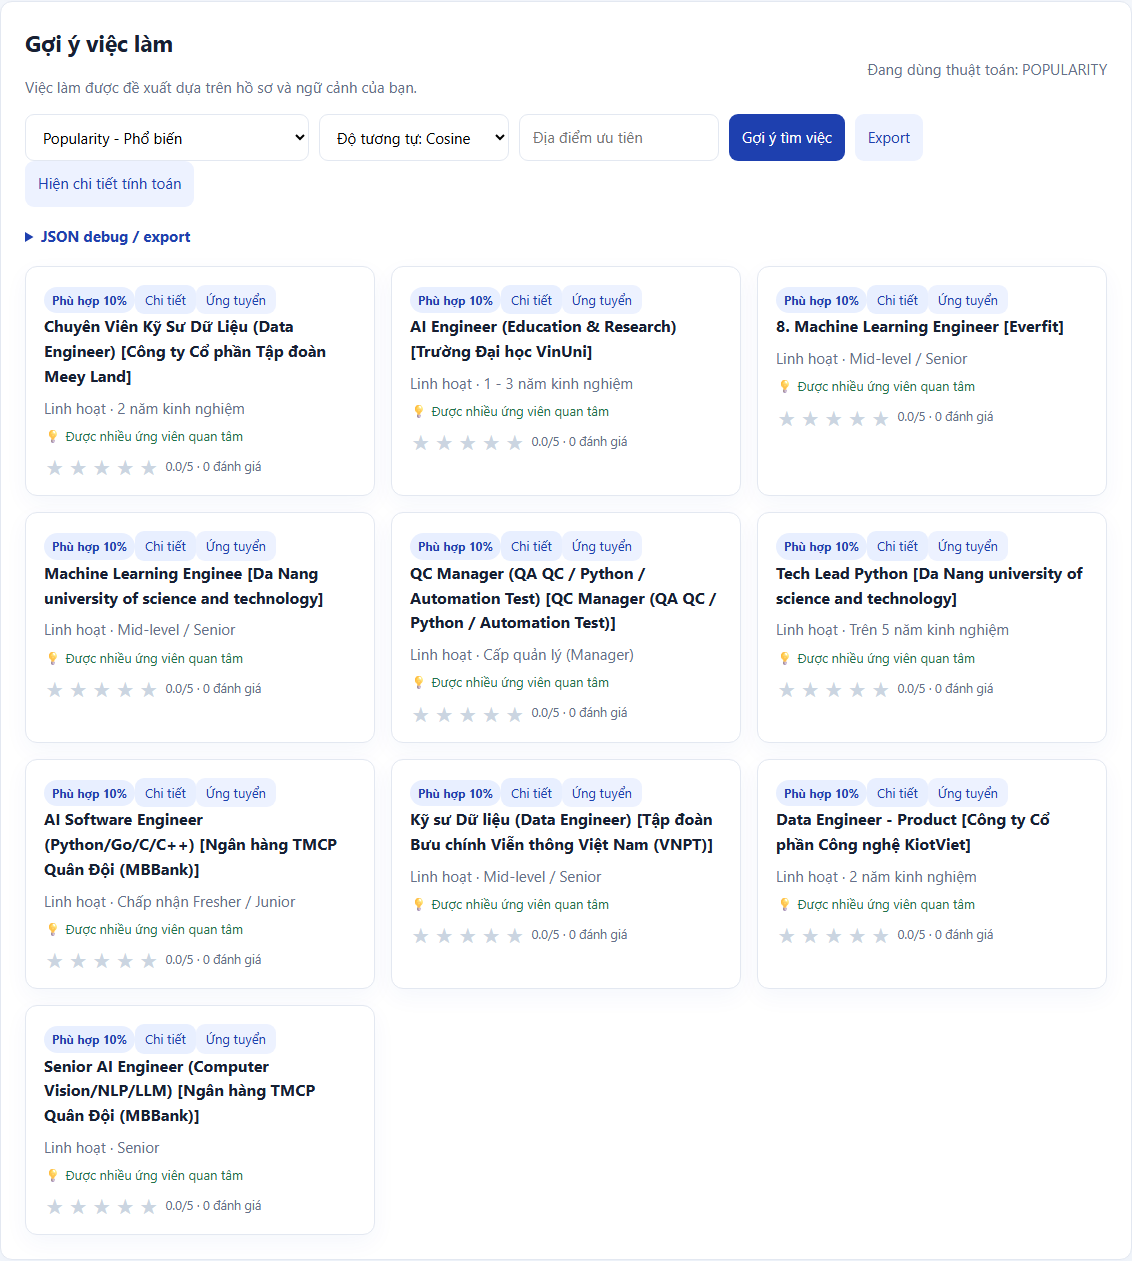

In [9]:
display(recs[recs.algorithm.eq("popularity")][["rank","job_id","title","score","score_type","fallback"]])
display(metrics[metrics.algorithm.eq("popularity")][["k","test_users","hit_rate","recall","ndcg","catalog_coverage","fallback_fraction","rmse_positive_holdout","mae_positive_holdout"]])
cap=next(c for c in captures if c["algorithm"]=="popularity" and c["similarity"]=="cosine")
display(Markdown(f"Website trả **{cap['n_items']}** kết quả, HTTP {cap['http_status']}; thời điểm UTC {cap['captured_at']}."))
display(Image(filename=cap["screenshot"],width=1000))

## 4 7 Model based CF SGD
$\hat r_{uj}=\mu+b_u+b_j+p_u^Tq_j$. Tối thiểu hóa sai số bình phương trên rating quan sát cùng regularization; cập nhật SGD 45 epoch, 12 nhân tố, learning rate 0.012, reg 0.04. User/job chưa huấn luyện dùng prior, không dùng vector ngẫu nhiên để xếp hạng.

Bảng sau là Top-10 của đúng user 458 trong snapshot trước thu ảnh. Ảnh là kết quả website có nhãn thuật toán đã kiểm tra; hai bên không có cam kết đồng nhất backend hoặc snapshot.

,rank,job_id,title,score,score_type,fallback
60,1,838,Java Fullstack Developer,4.467456,bayesian_rating_prior,popularity_untrained_user_or_item
61,2,1865,"AI Engineer (NLP, LLM, AI Agent)",4.467456,bayesian_rating_prior,popularity_untrained_user_or_item
62,3,1884,"AI Engineer (Python, LLM, RAG)",4.415516,bayesian_rating_prior,popularity_untrained_user_or_item
63,4,1899,Senior Python Developer / Backend Engineer,4.415516,bayesian_rating_prior,popularity_untrained_user_or_item
64,5,1901,AI / Machine Learning Engineer (Recommender Sy...,4.415516,bayesian_rating_prior,popularity_untrained_user_or_item
65,6,1878,Machine Learning Engineer,4.391378,bayesian_rating_prior,popularity_untrained_user_or_item
66,7,1903,Senior Fullstack Developer (Python & ReactJS),4.391378,bayesian_rating_prior,popularity_untrained_user_or_item
67,8,1945,Lập Trình Viên Ứng Dụng Đa Nền Tảng (Desktop/W...,4.391378,bayesian_rating_prior,popularity_untrained_user_or_item
68,9,1908,QA Automation Test Engineer (Python / Playwright),4.373964,bayesian_rating_prior,popularity_untrained_user_or_item
69,10,1894,Fresher AI Engineer (Đào tạo 3 tháng),4.342456,bayesian_rating_prior,popularity_untrained_user_or_item


,k,test_users,hit_rate,recall,ndcg,catalog_coverage,fallback_fraction,rmse_positive_holdout,mae_positive_holdout
12,5,11,0.090909,0.090909,0.039152,0.013962,0.0,0.627342,0.522913
13,10,11,0.181818,0.181818,0.067831,0.024433,0.0,0.627342,0.522913


Website trả **0** kết quả, HTTP 200; thời điểm UTC 2026-10-28T07:42:48.242Z.

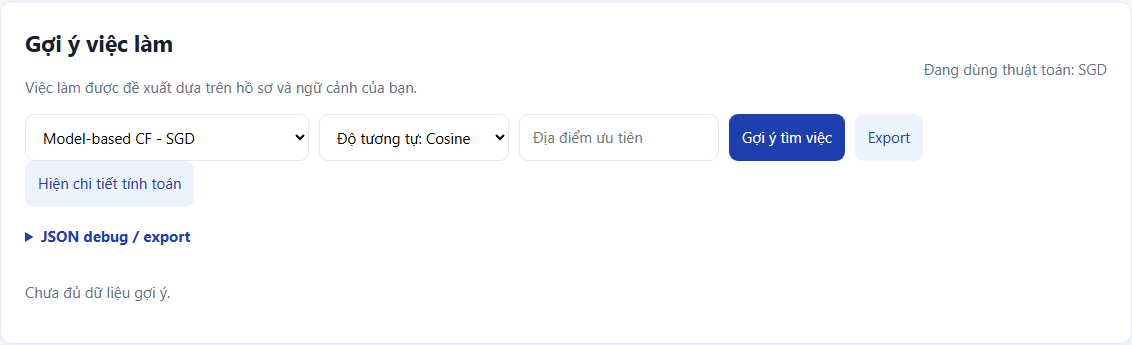

In [10]:
display(recs[recs.algorithm.eq("sgd")][["rank","job_id","title","score","score_type","fallback"]])
display(metrics[metrics.algorithm.eq("sgd")][["k","test_users","hit_rate","recall","ndcg","catalog_coverage","fallback_fraction","rmse_positive_holdout","mae_positive_holdout"]])
cap=next(c for c in captures if c["algorithm"]=="sgd" and c["similarity"]=="cosine")
display(Markdown(f"Website trả **{cap['n_items']}** kết quả, HTTP {cap['http_status']}; thời điểm UTC {cap['captured_at']}."))
display(Image(filename=cap["screenshot"],width=1000))

## 4 8 ALS Explicit
$\hat r_{uj}=\mu+p_u^Tq_j$. Luân phiên giải ridge trên các rating quan sát sau khi trừ trung bình; 12 nhân tố, 12 vòng, reg=0.4. Không áp dụng loss cho các ô thiếu; không clip dự đoán.

Bảng sau là Top-10 của đúng user 458 trong snapshot trước thu ảnh. Ảnh là kết quả website có nhãn thuật toán đã kiểm tra; hai bên không có cam kết đồng nhất backend hoặc snapshot.

,rank,job_id,title,score,score_type,fallback
70,1,838,Java Fullstack Developer,4.467456,bayesian_rating_prior,popularity_untrained_user_or_item
71,2,1865,"AI Engineer (NLP, LLM, AI Agent)",4.467456,bayesian_rating_prior,popularity_untrained_user_or_item
72,3,1884,"AI Engineer (Python, LLM, RAG)",4.415516,bayesian_rating_prior,popularity_untrained_user_or_item
73,4,1899,Senior Python Developer / Backend Engineer,4.415516,bayesian_rating_prior,popularity_untrained_user_or_item
74,5,1901,AI / Machine Learning Engineer (Recommender Sy...,4.415516,bayesian_rating_prior,popularity_untrained_user_or_item
75,6,1878,Machine Learning Engineer,4.391378,bayesian_rating_prior,popularity_untrained_user_or_item
76,7,1903,Senior Fullstack Developer (Python & ReactJS),4.391378,bayesian_rating_prior,popularity_untrained_user_or_item
77,8,1945,Lập Trình Viên Ứng Dụng Đa Nền Tảng (Desktop/W...,4.391378,bayesian_rating_prior,popularity_untrained_user_or_item
78,9,1908,QA Automation Test Engineer (Python / Playwright),4.373964,bayesian_rating_prior,popularity_untrained_user_or_item
79,10,1894,Fresher AI Engineer (Đào tạo 3 tháng),4.342456,bayesian_rating_prior,popularity_untrained_user_or_item


,k,test_users,hit_rate,recall,ndcg,catalog_coverage,fallback_fraction,rmse_positive_holdout,mae_positive_holdout
14,5,11,0.181818,0.181818,0.074321,0.032286,0.0,0.562997,0.46287
15,10,11,0.363636,0.363636,0.131990,0.043630,0.0,0.562997,0.46287


Website trả **0** kết quả, HTTP 200; thời điểm UTC 2026-10-28T07:43:18.479Z.

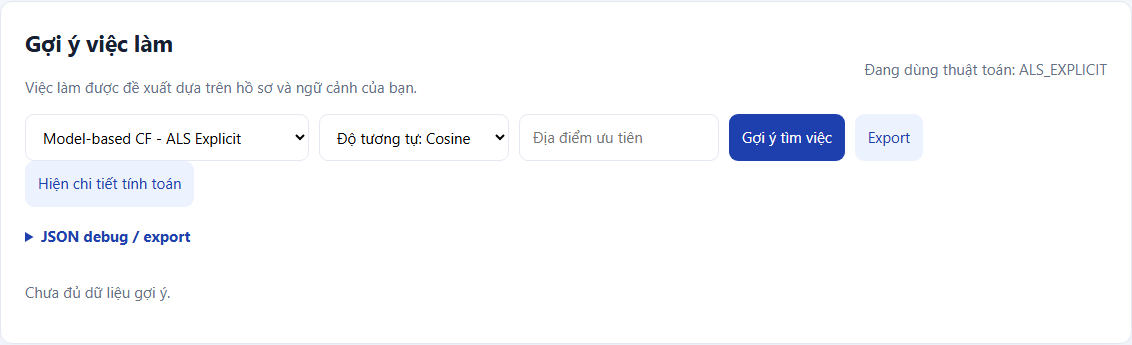

In [11]:
display(recs[recs.algorithm.eq("als_explicit")][["rank","job_id","title","score","score_type","fallback"]])
display(metrics[metrics.algorithm.eq("als_explicit")][["k","test_users","hit_rate","recall","ndcg","catalog_coverage","fallback_fraction","rmse_positive_holdout","mae_positive_holdout"]])
cap=next(c for c in captures if c["algorithm"]=="als_explicit" and c["similarity"]=="cosine")
display(Markdown(f"Website trả **{cap['n_items']}** kết quả, HTTP {cap['http_status']}; thời điểm UTC {cap['captured_at']}."))
display(Image(filename=cap["screenshot"],width=1000))

## 4 9 ALS Implicit
$P_{uj}=1[B_{uj}>0]$, $C_{uj}=1+16B_{uj}$. Tối thiểu hóa $\sum_{u,j} C_{uj}(P_{uj}-p_u^Tq_j)^2+0.7(\|p_u\|^2+\|q_j\|^2)$; 12 nhân tố, 10 vòng. Rating thấp không tạo preference dương. Đây là affinity, không phải rating và không tính RMSE cho nó.

Bảng sau là Top-10 của đúng user 458 trong snapshot trước thu ảnh. Ảnh là kết quả website có nhãn thuật toán đã kiểm tra; hai bên không có cam kết đồng nhất backend hoặc snapshot.

,rank,job_id,title,score,score_type,fallback
80,1,838,Java Fullstack Developer,4.467456,bayesian_rating_prior,popularity_no_positive_signal
81,2,1865,"AI Engineer (NLP, LLM, AI Agent)",4.467456,bayesian_rating_prior,popularity_no_positive_signal
82,3,1884,"AI Engineer (Python, LLM, RAG)",4.415516,bayesian_rating_prior,popularity_no_positive_signal
83,4,1899,Senior Python Developer / Backend Engineer,4.415516,bayesian_rating_prior,popularity_no_positive_signal
84,5,1901,AI / Machine Learning Engineer (Recommender Sy...,4.415516,bayesian_rating_prior,popularity_no_positive_signal
85,6,1878,Machine Learning Engineer,4.391378,bayesian_rating_prior,popularity_no_positive_signal
86,7,1903,Senior Fullstack Developer (Python & ReactJS),4.391378,bayesian_rating_prior,popularity_no_positive_signal
87,8,1945,Lập Trình Viên Ứng Dụng Đa Nền Tảng (Desktop/W...,4.391378,bayesian_rating_prior,popularity_no_positive_signal
88,9,1908,QA Automation Test Engineer (Python / Playwright),4.373964,bayesian_rating_prior,popularity_no_positive_signal
89,10,1894,Fresher AI Engineer (Đào tạo 3 tháng),4.342456,bayesian_rating_prior,popularity_no_positive_signal


,k,test_users,hit_rate,recall,ndcg,catalog_coverage,fallback_fraction,rmse_positive_holdout,mae_positive_holdout
16,5,11,0.363636,0.363636,0.318182,0.032286,0.0,NaN,NaN
17,10,11,0.545455,0.545455,0.374227,0.048866,0.0,NaN,NaN


Website trả **0** kết quả, HTTP 200; thời điểm UTC 2026-10-28T07:46:20.699Z.

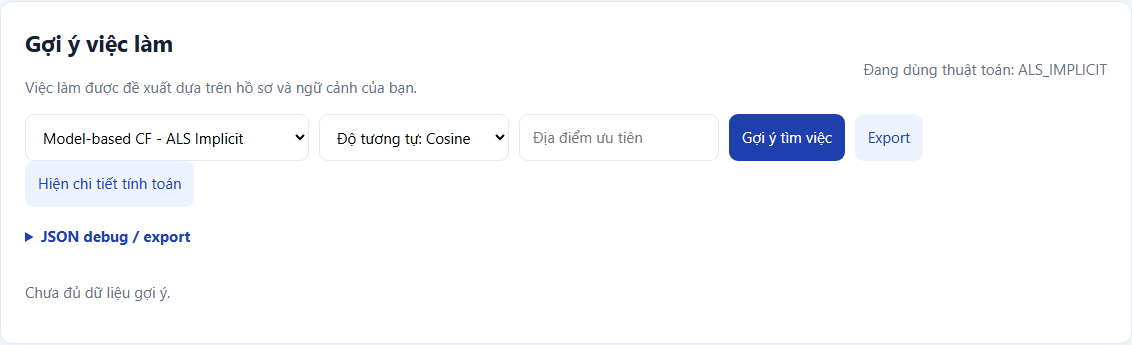

In [12]:
display(recs[recs.algorithm.eq("als_implicit")][["rank","job_id","title","score","score_type","fallback"]])
display(metrics[metrics.algorithm.eq("als_implicit")][["k","test_users","hit_rate","recall","ndcg","catalog_coverage","fallback_fraction","rmse_positive_holdout","mae_positive_holdout"]])
cap=next(c for c in captures if c["algorithm"]=="als_implicit" and c["similarity"]=="cosine")
display(Markdown(f"Website trả **{cap['n_items']}** kết quả, HTTP {cap['http_status']}; thời điểm UTC {cap['captured_at']}."))
display(Image(filename=cap["screenshot"],width=1000))

## 5 Đánh giá ngoại tuyến không rò rỉ
Do rating không có thời gian đáng tin cậy, dùng random positive leave-one-out với seed 42. User cần ít nhất 3 rating; giữ một rating ≥4 cho test, job test phải mở và còn ít nhất một rating train từ user khác. Xóa mọi lượt xem của chính cặp test khỏi train.

HitRate là tỷ lệ user tìm được ít nhất một mục đúng; Recall là tỷ lệ mục relevant được thu hồi. Mỗi user chỉ có một test item nên HR=Recall. NDCG dùng chiết khấu log2 theo hạng. Coverage là số job được gợi ý / số job mở. Báo cáo tỷ lệ fallback và số mẫu cùng metrics. RMSE/MAE chỉ cho phương pháp dự đoán rating, trên **holdout tích cực**, không suy ra chất lượng trên toàn thang rating hoặc độ phù hợp cá nhân hiện tại.

{'strategy': 'positive_leave_one_out_random', 'seed': 42, 'test_users': 11, 'test_ratings': 11, 'train_ratings': 158, 'excluded_users': 2, 'removed_view_pairs': 0, 'limitation': 'No trustworthy rating time. Positive-only holdout; RMSE/MAE are not all-rating accuracy. Static catalog/profile metadata available at snapshot.'}


,source,algorithm,k,test_users,hit_rate,recall,ndcg,catalog_coverage,fallback_fraction
0,provided_snapshot,cbf,5,34,0.147059,0.147059,0.100902,0.056962,0.000000
1,provided_snapshot,cbf,10,34,0.176471,0.176471,0.109756,0.106329,0.000000
2,provided_snapshot,cf,5,34,0.176471,0.176471,0.114092,0.041772,0.000000
3,provided_snapshot,cf,10,34,0.382353,0.382353,0.180936,0.049367,0.000000
4,provided_snapshot,hybrid,5,34,0.176471,0.176471,0.096808,0.056962,0.000000
5,provided_snapshot,hybrid,10,34,0.294118,0.294118,0.137092,0.081013,0.000000
6,provided_snapshot,user_knn,5,34,0.323529,0.323529,0.301819,0.051899,0.735294
7,provided_snapshot,user_knn,10,34,0.382353,0.382353,0.319175,0.053165,0.867647
8,provided_snapshot,item_knn,5,34,0.323529,0.323529,0.301819,0.051899,0.735294
9,provided_snapshot,item_knn,10,34,0.382353,0.382353,0.319175,0.053165,0.867647


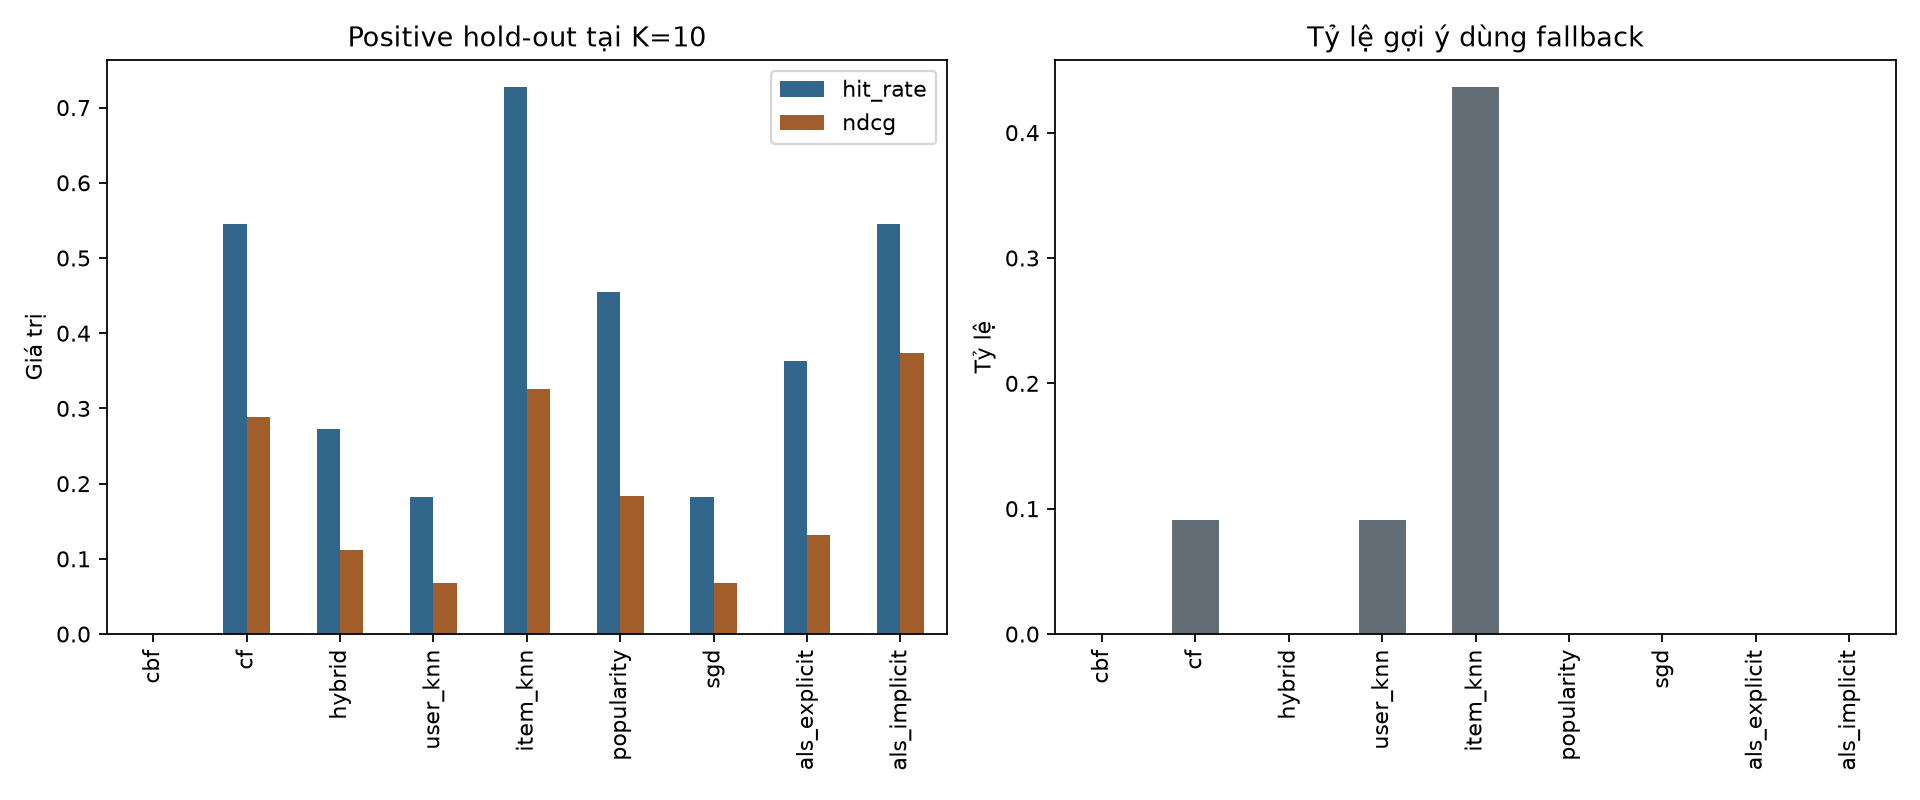

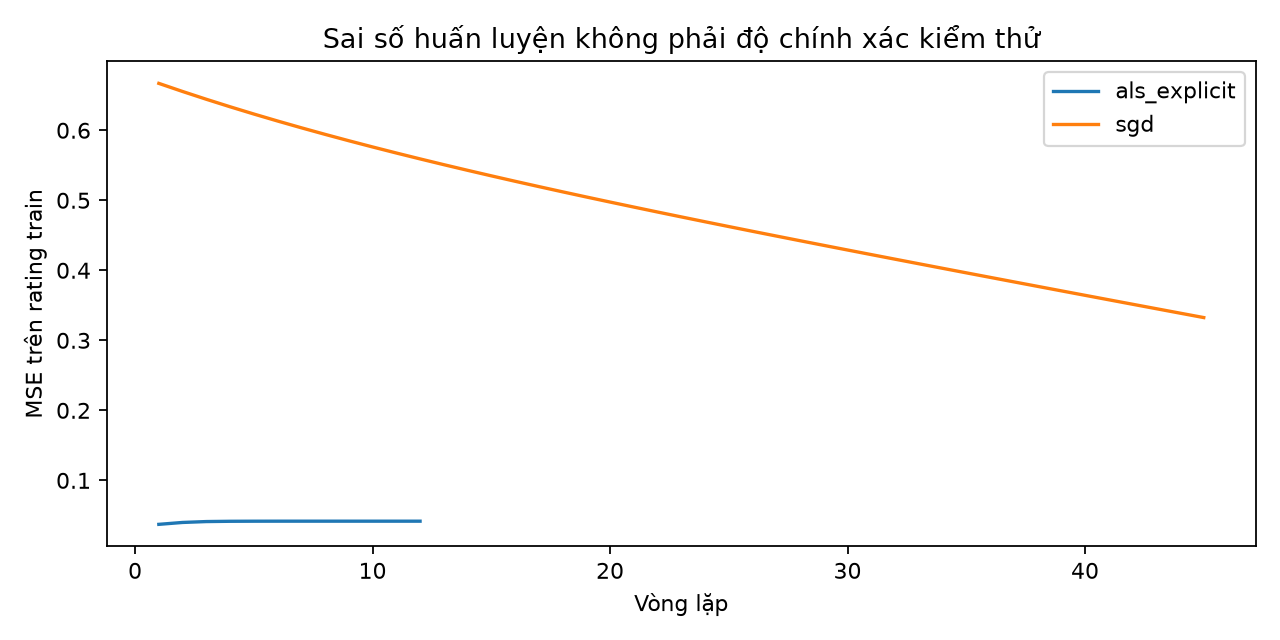

In [13]:
train,test,split = positive_holdout(data,config)
held=set(zip(test.user_id,test.job_id))
assert not held.intersection(zip(train.ratings.user_id,train.ratings.job_id))
assert not held.intersection(zip(train.views.user_id,train.views.job_id))
print({k:v for k,v in split.items() if k not in ["exclusions"]})
all_metrics=pd.concat([r[3].assign(source=label) for label,r in runs.items()],ignore_index=True)
display(all_metrics[["source","algorithm","k","test_users","hit_rate","recall","ndcg","catalog_coverage","fallback_fraction"]])
display(Image(filename="outputs/notebook/website_before/figures/offline_metrics.png"))
display(Image(filename="outputs/notebook/provided_snapshot/figures/training_loss.png"))

## 6 Đối sánh website và Python
So theo job ID, không theo tiêu đề hoặc thang điểm. Có số kết quả thực, giao nhau, Jaccard và chênh lệch hạng của job chung. `Overlap@10` không tính khi một bên ít hơn 10. HTTP lỗi hoặc thiếu capture là unavailable, không phải danh sách rỗng thành công. Website trả 0 kết quả với 6 phương pháp khi tài khoản chưa có tương tác; không kết luận backend sai.

`candidate_count` website và số job mở trong CSV có thể khác; diagnostics chỉ xuất 50 dòng mẫu nên không đủ chứng minh cùng tập ứng viên. Các bảng này là đối chiếu tham khảo, không phải phép kiểm chứng tái tạo backend. CBF Pearson được chụp ở phiên khôi phục muộn hơn, có timestamp riêng.

,algorithm,similarity,requested_k,n_web,n_python,intersection,overlap_at_k,jaccard,top1_match,mean_absolute_rank_delta_common,same_user,capture_id,captured_at,comparison_status
0,cbf,cosine,10,10,10,0,0.0,0.0,False,None,True,cbf_cosine,2026-10-28T07:46:55.843Z,reference_only_backend_and_snapshot_not_proven
1,cf,cosine,10,0,10,0,NaN,0.0,None,None,True,cf_cosine,2026-10-28T07:39:57.923Z,reference_only_backend_and_snapshot_not_proven
2,hybrid,cosine,10,10,10,0,0.0,0.0,False,None,True,hybrid_cosine,2026-10-28T07:40:39.620Z,reference_only_backend_and_snapshot_not_proven
3,user_knn,cosine,10,0,10,0,NaN,0.0,None,None,True,user_knn_cosine,2026-10-28T07:41:50.756Z,reference_only_backend_and_snapshot_not_proven
4,item_knn,cosine,10,0,10,0,NaN,0.0,None,None,True,item_knn_cosine,2026-10-28T07:42:22.099Z,reference_only_backend_and_snapshot_not_proven
5,popularity,cosine,10,10,10,0,0.0,0.0,False,None,True,popularity_cosine,2026-10-28T07:39:01.957Z,reference_only_backend_and_snapshot_not_proven
6,sgd,cosine,10,0,10,0,NaN,0.0,None,None,True,sgd_cosine,2026-10-28T07:42:48.242Z,reference_only_backend_and_snapshot_not_proven
7,als_explicit,cosine,10,0,10,0,NaN,0.0,None,None,True,als_explicit_cosine,2026-10-28T07:43:18.479Z,reference_only_backend_and_snapshot_not_proven
8,als_implicit,cosine,10,0,10,0,NaN,0.0,None,None,True,als_implicit_cosine,2026-10-28T07:46:20.699Z,reference_only_backend_and_snapshot_not_proven


,algorithm,job_id,web_rank,python_rank,rank_delta
0,cbf,481,10.0,NaN,None
1,cbf,484,9.0,NaN,None
2,cbf,487,8.0,NaN,None
3,cbf,491,7.0,NaN,None
4,cbf,498,6.0,NaN,None
5,cbf,501,5.0,NaN,None
6,cbf,767,4.0,NaN,None
7,cbf,838,NaN,1.0,None
8,cbf,1865,NaN,2.0,None
9,cbf,1878,NaN,6.0,None


,algorithm,similarity,n_items,candidate_count,captured_at
0,popularity,cosine,10,1157,2026-10-28T07:39:01.957Z
1,cf,cosine,0,1157,2026-10-28T07:39:57.923Z
2,hybrid,cosine,10,1157,2026-10-28T07:40:39.620Z
3,user_knn,cosine,0,1157,2026-10-28T07:41:50.756Z
4,item_knn,cosine,0,1157,2026-10-28T07:42:22.099Z
5,sgd,cosine,0,1157,2026-10-28T07:42:48.242Z
6,als_explicit,cosine,0,1157,2026-10-28T07:43:18.479Z
7,als_implicit,cosine,0,1157,2026-10-28T07:46:20.699Z
8,cbf,cosine,10,1157,2026-10-28T07:46:55.843Z
9,cbf,jaccard,10,1157,2026-10-28T07:47:32.180Z


,algorithm,similarity,requested_k,n_web,n_python,intersection,overlap_at_k,jaccard,top1_match,mean_absolute_rank_delta_common,same_user,capture_id,captured_at,comparison_status
0,cbf,cosine,10,10,10,0,0.0,0.0,False,None,True,cbf_cosine,2026-10-28T07:46:55.843Z,reference_only_backend_and_snapshot_not_proven


,algorithm,similarity,requested_k,n_web,n_python,intersection,overlap_at_k,jaccard,top1_match,mean_absolute_rank_delta_common,same_user,capture_id,captured_at,comparison_status
0,cbf,jaccard,10,10.0,10,0.0,0.0,0.0,False,None,True,cbf_jaccard,2026-10-28T07:47:32.180Z,reference_only_backend_and_snapshot_not_proven


,algorithm,similarity,requested_k,n_web,n_python,intersection,overlap_at_k,jaccard,top1_match,mean_absolute_rank_delta_common,same_user,capture_id,captured_at,comparison_status
0,cbf,pearson,10,10.0,10,0.0,0.0,0.0,False,None,True,cbf_pearson,2026-10-28T12:35:01.001Z,reference_only_backend_and_snapshot_not_proven


,similarity,rank,job_id,score_type,fallback
0,cosine,1,838,bayesian_rating_prior,popularity_missing_profile
1,cosine,2,1865,bayesian_rating_prior,popularity_missing_profile
2,cosine,3,1884,bayesian_rating_prior,popularity_missing_profile
3,cosine,4,1899,bayesian_rating_prior,popularity_missing_profile
4,cosine,5,1901,bayesian_rating_prior,popularity_missing_profile
5,cosine,6,1878,bayesian_rating_prior,popularity_missing_profile
6,cosine,7,1903,bayesian_rating_prior,popularity_missing_profile
7,cosine,8,1945,bayesian_rating_prior,popularity_missing_profile
8,cosine,9,1908,bayesian_rating_prior,popularity_missing_profile
9,cosine,10,1894,bayesian_rating_prior,popularity_missing_profile


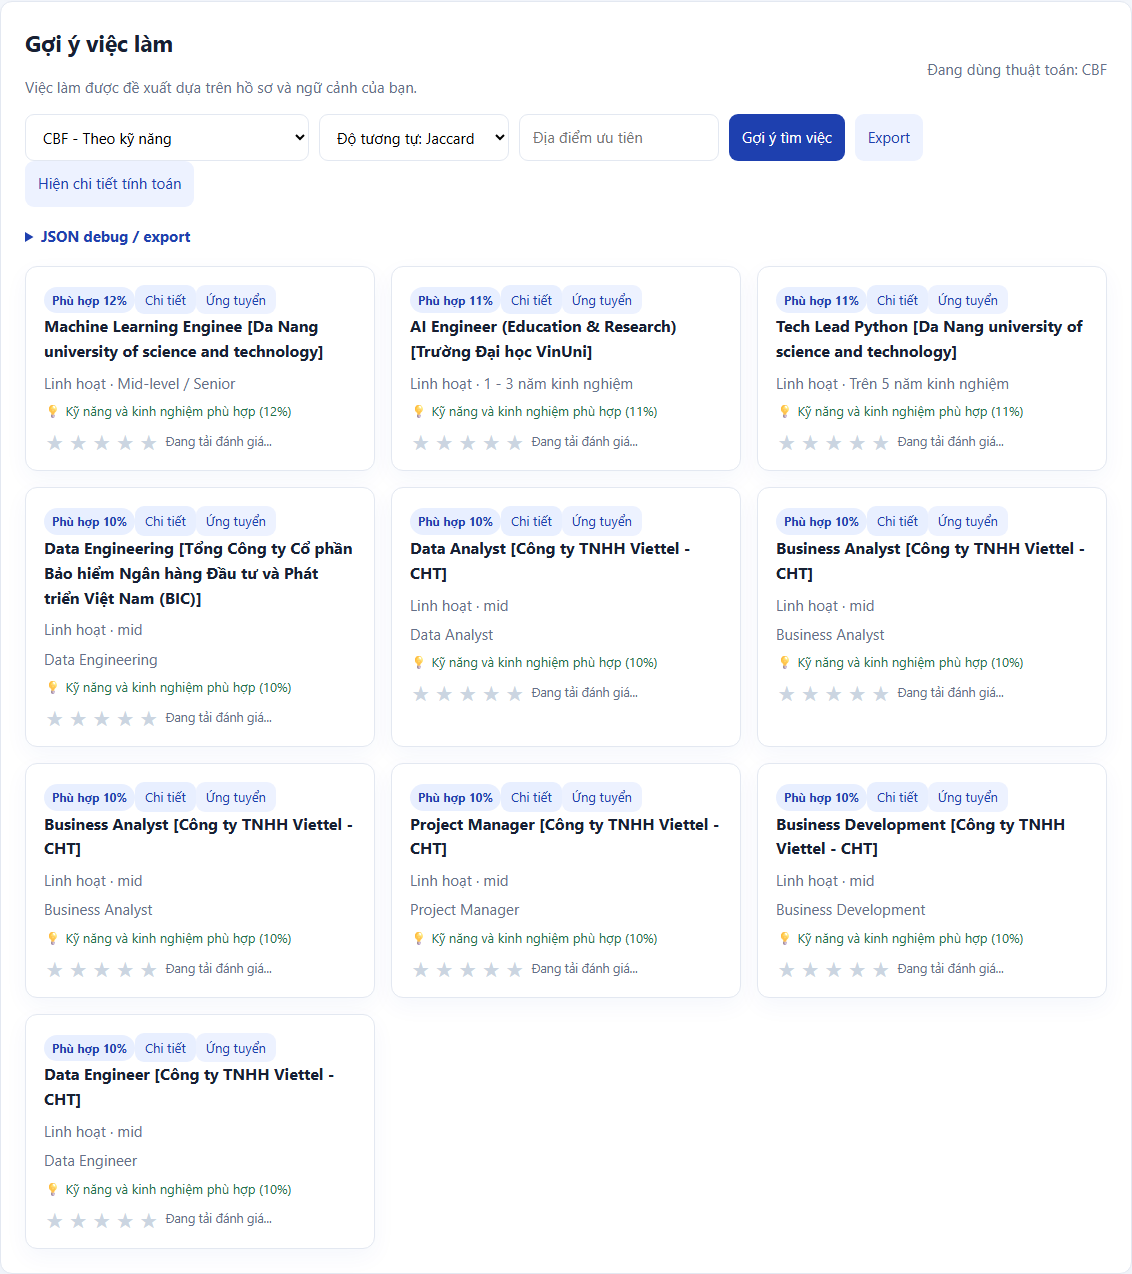

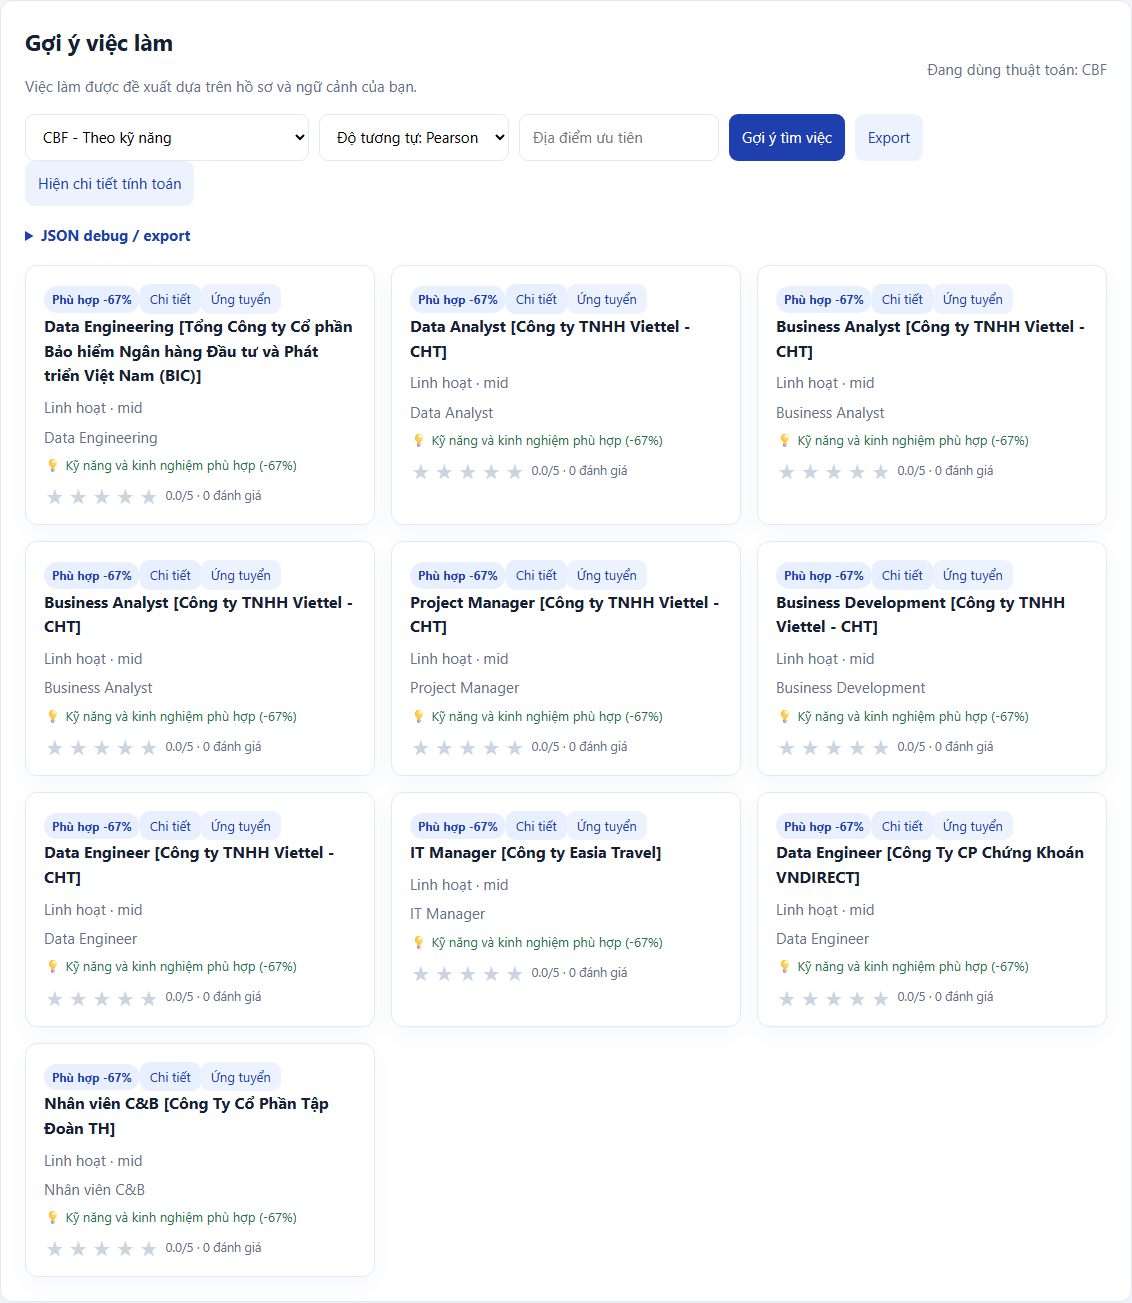

In [14]:
comparison,ranks=compare_website(web,recs,captures=captures,target_user_id=target_id)
display(comparison)
display(ranks.head(20))
display(pd.DataFrame(captures)[["algorithm","similarity","n_items","candidate_count","captured_at"]])
cbf_results=[]
for similarity in ["cosine","jaccard","pearson"]:
    s=RecommenderSuite(replace(config,similarity=similarity)).fit(data)
    r=s.recommend(target_id,algorithms=["cbf"])
    r["similarity"]=similarity
    cbf_results.append(r)
    c,_=compare_website(web,r,captures=captures,similarity=similarity,target_user_id=target_id)
    display(c[c.algorithm.eq("cbf")])
cbf_results=pd.concat(cbf_results,ignore_index=True)
cbf_results.to_csv("outputs/notebook/cbf_similarity.csv",index=False,encoding="utf-8-sig")
display(cbf_results[["similarity","rank","job_id","score_type","fallback"]])
for similarity in ["jaccard","pearson"]:
    c=next(c for c in captures if c["algorithm"]=="cbf" and c["similarity"]==similarity)
    display(Image(filename=c["screenshot"],width=1000))

## 7 Nhận xét và công việc cần dữ liệu bổ sung
Chín thuật toán chạy trên cùng quy tắc và train/test trong từng snapshot. Các mô hình cộng tác bị giới hạn bởi độ thưa, ít user có rating và cold-start. Tài khoản sinh viên chưa có hồ sơ/rating, nên 80/90 dòng Python của snapshot website là fallback (Popularity là baseline model). Không có căn cứ khẳng định các việc này phù hợp sở thích cá nhân.

Đăng 10 tin, chuẩn hóa hồ sơ và tạo rating còn chờ xác nhận nội dung thật. Không đưa kỹ năng suy đoán hoặc rating do hệ thống tự bịa vào dữ liệu. Mật khẩu do người dùng tự đổi. Xem `STATUS.md` cho trạng thái hoàn thành và `data/import/IMPORT_PREVIEW.md` cho danh sách chờ duyệt.

Nguồn: đề LabDSS WebsiteRECSYS do giảng viên cung cấp; website RECSYS; nguồn tuyển dụng gốc Bosch/KMS trong danh sách import; source Python của gói này là định nghĩa chính xác các biến thể đã chạy.